In [ ]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
df = pd.read_csv("Telco_Customer_Churn_Dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("Telco_Customer_Churn_Dataset.csv")


df.shape; df.info(); df.describe(); df.head()

#  Fix TotalCharges (text -> number); blanks become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isnull().sum())

#  Handle missing values
df["TotalCharges"] = df["TotalCharges"].fillna(0)

#  Drop the ID column and encode the target
df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

#  Encode categorical variables
df_encoded = pd.get_dummies(df, drop_first=True)

#  Split
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

# Scale numeric columns (needed for logistic regression)
num = ["tenure","MonthlyCharges","TotalCharges"]
sc = StandardScaler()
X_train[num] = sc.fit_transform(X_train[num])
X_test[num]  = sc.transform(X_test[num])

models = {
  "Logistic Regression": LogisticRegression(max_iter=1000),
  "Decision Tree": DecisionTreeClassifier(random_state=42),
  "Random Forest": RandomForestClassifier(random_state=42)
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, accuracy_score(y_test, m.predict(X_test)))
    print(classification_report(y_test, m.predict(X_test)))

# Hyperparameter tuning
grid = GridSearchCV(RandomForestClassifier(random_state=42),
    {"n_estimators":[100,200], "max_depth":[5,10,None], "min_samples_split":[2,5]},
    cv=5, scoring="f1")
grid.fit(X_train, y_train)
best = grid.best_estimator_

Logistic Regression 0.8062455642299503
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Decision Tree 0.7253371185237757
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1035
           1       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.72      0.73      0.72      1409

Random Forest 0.7849538679914834
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72

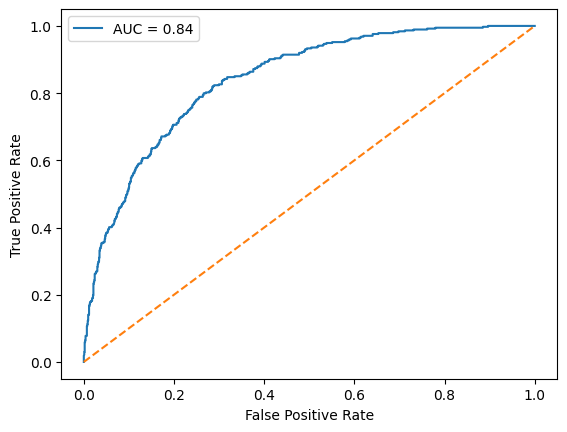

<Axes: >

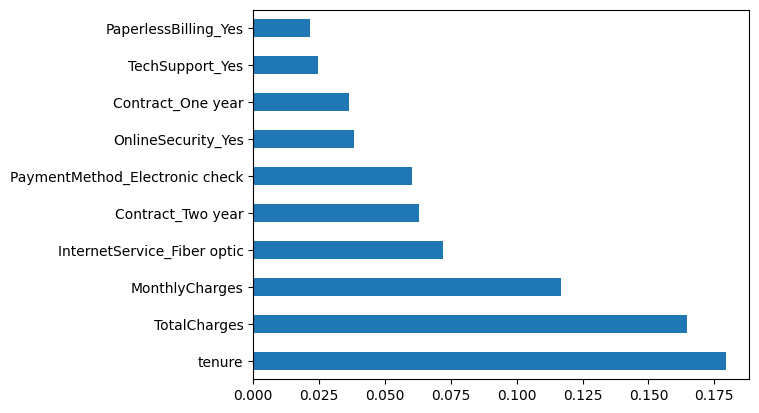

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

probs = best.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, probs)
auc = roc_auc_score(y_test, probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}"); plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend(); plt.show()

# Feature importance
imp = pd.Series(best.feature_importances_, index=X.columns).nlargest(10)
imp.plot(kind="barh")

In [ ]:
import pandas as pd
df = pd.read_csv("Telco_Customer_Churn_Dataset.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
# ---- Current situation ----
total_customers = len(df)
churned = df[df["Churn"] == "Yes"]
churn_rate = len(churned) / total_customers * 100
avg_monthly = churned["MonthlyCharges"].mean()
monthly_loss = churned["MonthlyCharges"].sum()
print(f"Current churn rate: {churn_rate:.1f}%")
print(f"Customers lost: {len(churned)}")
print(f"Monthly revenue lost: ${monthly_loss:,.0f}")
print(f"Yearly revenue lost: ${monthly_loss*12:,.0f}")
# ---- Scenario: retention actions save a % of churners ----
discount_cost = 0.10          # assume retention offer costs 10% of the monthly bill
results = []
for save_pct in [0.10, 0.20, 0.30]:
    saved = len(churned) * save_pct
    new_churn_rate = (len(churned) - saved) / total_customers * 100
    revenue_saved = saved * avg_monthly * 12
    offer_cost = saved * avg_monthly * discount_cost * 12
    results.append({
        "Churners saved": f"{int(save_pct*100)}%",
        "Customers saved": round(saved),
        "New churn rate %": round(new_churn_rate, 1),
        "Yearly revenue saved ($)": round(revenue_saved),
        "Offer cost ($)": round(offer_cost),
        "Net gain ($)": round(revenue_saved - offer_cost),
    })

impact = pd.DataFrame(results)
print(impact)

Current churn rate: 26.5%
Customers lost: 1869
Monthly revenue lost: $139,131
Yearly revenue lost: $1,669,570
  Churners saved  Customers saved  New churn rate %  Yearly revenue saved ($)  \
0            10%              187              23.9                    166957   
1            20%              374              21.2                    333914   
2            30%              561              18.6                    500871   

   Offer cost ($)  Net gain ($)  
0           16696        150261  
1           33391        300523  
2           50087        450784  


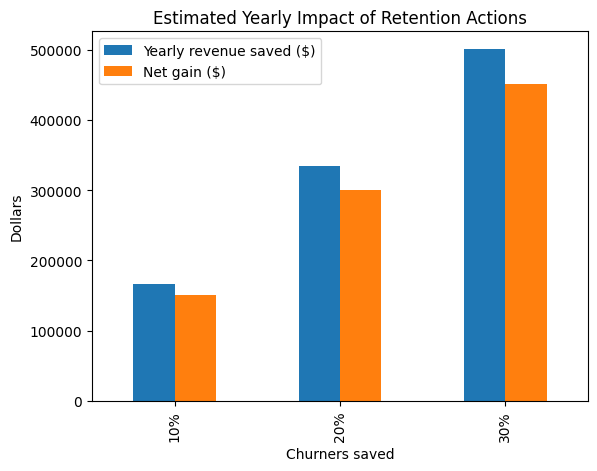

In [ ]:
import matplotlib.pyplot as plt
impact.plot(x="Churners saved", y=["Yearly revenue saved ($)", "Net gain ($)"], kind="bar")
plt.title("Estimated Yearly Impact of Retention Actions")
plt.ylabel("Dollars")
plt.show()